# Lab 4 — Tokens, Masks and an Encoder Transformer

**Unit.** `chapter_12_transformers` · **Duration.** 1 hour

A pretrained BERT, thirty ordinary sentences, and nothing to train. The unit built the
transformer on paper; this lab attaches its objects to tensors you can print.

1. Turn a string into sub-word tokens, indices, and embedding vectors.
2. Hide a token behind `[MASK]` and ask the model what it was — once in detail, then over
   the whole corpus as an accuracy.
3. Pull out the attention matrix and find the head that routes the masked position's
   attention onto the word that gives the answer away.

The unit places BERT in the **encoder** family, trained by **masked language modelling**.
By the end of Exercise 2 you will have run that objective yourself and measured how often
it succeeds.

Work through the cells in order. Each cell marked **Your turn** is followed by a CHECK
cell that prints `[ok]` when you have it right.

## Setup

Provided. Downloads `bert-base-uncased` through the Hugging Face API — about 440 MB, once
per session, cached under `lab4/data/hf/` — then prints the model's shape and shows what
the tokenizer does to the first three sentences.

On Colab the first cell installs `transformers`; running locally it does nothing.

In [ ]:
# COLAB SETUP -- run this cell first.  Outside Colab it does nothing.
import importlib.util
import subprocess
import sys
import urllib.request

try:  # find_spec raises when the parent package is absent, so import instead
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Colab already ships torch and torchvision; install only what is missing.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "lightning", "torchmetrics", "transformers==5.22.1"], check=True)

# Fetch the lab's support module when it is not already beside the notebook.
if importlib.util.find_spec("lab4_utils") is None:
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/kenpu-uoit/csci4052u-machine-learning-2/main/labs/lab4/lab4_utils.py", "lab4_utils.py")
    print("downloaded lab4_utils.py")


downloaded lab4_utils.py


In [ ]:
import torch

from lab4_utils import (
    DEMO, DEMO_FACT, DEMO_VAGUE, MASK_RATE, SENTENCES,
    describe, load_bert, mask_positions, show_attention, show_predictions,
    check_tokenize, check_embeddings, check_one_mask, check_accuracy,
    check_prediction_figure, check_attention, check_routing,
)

torch.manual_seed(0)

tokenizer, model = load_bert()
describe(tokenizer, model)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

bert-base-uncased: 110M parameters
  layers      12
  heads/layer 12
  hidden size 768
  vocabulary  30522
  mask token  '[MASK]' = id 103


In [ ]:
# What the tokenizer does, on the first three sentences of the corpus.
for s in SENTENCES[:3]:
    print(s)
    print("   ", tokenizer.tokenize(s))

print()
print("DEMO       :", DEMO)
print("DEMO_FACT  :", DEMO_FACT)
print("DEMO_VAGUE :", DEMO_VAGUE)

The capital city of France is Paris, and it sits on the river Seine.
    ['the', 'capital', 'city', 'of', 'france', 'is', 'paris', ',', 'and', 'it', 'sits', 'on', 'the', 'river', 'seine', '.']
Water boils at one hundred degrees Celsius at sea level pressure.
    ['water', 'boil', '##s', 'at', 'one', 'hundred', 'degrees', 'ce', '##ls', '##ius', 'at', 'sea', 'level', 'pressure', '.']
She opened the front door and stepped out into the cold morning air.
    ['she', 'opened', 'the', 'front', 'door', 'and', 'stepped', 'out', 'into', 'the', 'cold', 'morning', 'air', '.']

DEMO       : Tokenization splits unbelievably long words into subword pieces.
DEMO_FACT  : The capital city of France is Paris, and it sits on the river Seine.
DEMO_VAGUE : The restaurant on the corner serves the best pizza in the whole city.


---

# Exercise 1 — From a string to what the transformer sees

A transformer does not consume text. It consumes a sequence of vectors, and the two steps
that get there are **sub-word tokenization** and an **embedding lookup**.

### 1a · Tokens and indices — *Your turn*

Write `tokenize(text)` returning a list of `(token, id)` pairs for one string, **including
the special tokens** `[CLS]` and `[SEP]` that BERT frames every input with. Apply it to
`DEMO` and print the result.

Two calls do the whole job:

- `tokenizer(text)["input_ids"]` gives the indices, with the special tokens already added.
- `tokenizer.convert_ids_to_tokens(ids)` gives the matching strings.

In [ ]:
def tokenize(text):
    # 1. get the input ids for `text` -- tokenizer(text)["input_ids"]
    ids = tokenizer(text)["input_ids"]
    # 2. turn those ids back into token strings
    tokens = tokenizer.convert_ids_to_tokens(ids)
    # 3. return them zipped together as a list of (token, id) pairs
    return list(zip(tokens, ids))

demo_pairs = tokenize(DEMO)
for token, index in demo_pairs:
    print(f"{index:>6}  {token}")

   101  [CLS]
 19204  token
  3989  ##ization
 19584  splits
  4895  un
  8671  ##bel
  2666  ##ie
  3567  ##va
  6321  ##bly
  2146  long
  2616  words
  2046  into
  4942  sub
 18351  ##word
  4109  pieces
  1012  .
   102  [SEP]


In [ ]:
check_tokenize(tokenize, tokenizer)

[ok] 1a: 17 tokens, 6 of them '##' continuation pieces: ['##ization', '##bel', '##ie', '##va', '##bly', '##word']
     Sub-word tokenization: a word the vocabulary does not hold is spelled out of pieces it does.


### 1b · The embedding lookup — *Your turn*

Every index is a row number. Fetch the embedding matrix with
`model.get_input_embeddings().weight`, report its shape, and build `demo_embedded`: the
`DEMO` sentence as one vector per token.

The lookup is `embedding_matrix[ids]`, where `ids` is a tensor of the indices from 1a.
Keep the result two-dimensional — one row per token, no batch dimension.

In [ ]:
# 1. embedding_matrix = the weight of model.get_input_embeddings()
embedding_matrix = model.get_input_embeddings().weight

# 2. ids = a 1-D LongTensor of the indices in demo_pairs
ids = torch.tensor([idx for token, idx in demo_pairs], dtype=torch.long)

# 3. demo_embedded = the rows of the matrix at those ids
demo_embedded = embedding_matrix[ids]

# 4. print both shapes
print("Embedding matrix shape:", embedding_matrix.shape)
print("Demo embedded shape:   ", demo_embedded.shape)

Embedding matrix shape: torch.Size([30522, 768])
Demo embedded shape:    torch.Size([17, 768])


In [ ]:
check_embeddings(embedding_matrix, demo_embedded, demo_pairs)

[ok] 1b: embedding matrix (30522, 768), DEMO embedded to (17, 768).
     30522 x 768 is 23.4M parameters before any transformer layer -- which is why the vocabulary size is a design choice.


---

# Exercise 2 — Masking, and predicting the missing token

BERT is an **encoder**: every position attends to every other, in both directions, with no
causal mask. That makes next-token prediction useless as a training objective — the answer
is visible — so BERT is trained by hiding tokens and predicting them from both sides.

Here you run that objective at inference time.

### 2a · One masked token — *Your turn*

In `DEMO_FACT`, replace the token `paris` with `tokenizer.mask_token_id`, run the model,
and read the five most likely tokens for that position with their probabilities.

The steps:

- tokenize `DEMO_FACT`, find the index of `"paris"` in the token list;
- copy the ids and write `tokenizer.mask_token_id` at that index;
- run `model(input_ids=masked.unsqueeze(0))` under `torch.no_grad()`;
- take `outputs.logits[0, position]`, apply `.softmax(-1)`, and `.topk(5)`.

Store the five token strings in `top_tokens` and the five probabilities in `top_probs`.

In [ ]:
fact_tokens = tokenizer.convert_ids_to_tokens(tokenizer(DEMO_FACT)["input_ids"])
fact_ids = torch.tensor(tokenizer(DEMO_FACT)["input_ids"])
position = fact_tokens.index("paris")
print("masking position", position, "which holds", repr(fact_tokens[position]))

# 1. masked_ids = a copy of fact_ids with mask_token_id at `position`
masked_ids = fact_ids.clone()
masked_ids[position] = tokenizer.mask_token_id

# 2. run the model on masked_ids.unsqueeze(0) under torch.no_grad()
with torch.no_grad():
    outputs = model(masked_ids.unsqueeze(0))

# 3. probs = softmax over the logits at `position`
logits = outputs.logits[0, position]
probs = torch.softmax(logits, dim=-1)

# 4. top = probs.topk(5); top_tokens = the strings, top_probs = the values as floats
top = probs.topk(5)
top_tokens = tokenizer.convert_ids_to_tokens(top.indices)
top_probs = top.values.tolist()

# Print results to verify
for token, prob in zip(top_tokens, top_probs):
    print(f"{token:<15} {prob:.4f}")

masking position 7 which holds 'paris'
paris           0.9527
seine           0.0125
lille           0.0098
rouen           0.0078
orleans         0.0044


In [ ]:
check_one_mask(top_tokens, top_probs)

[ok] 2a: 'paris' at p=0.953; runners-up [('seine', 0.013), ('lille', 0.01), ('rouen', 0.008), ('orleans', 0.004)]
     The masked position carries no information about its own token, so every bit of that came from the other positions. That is the encoder's bidirectional context.


### 2b · Accuracy over the corpus — *Your turn*

Now the same thing thirty times, at BERT's own pre-training rate of 15%.

For each sentence in `SENTENCES`:

- tokenize it and keep the unmasked ids — they are the answer key;
- `positions = mask_positions(len(ids))` gives the indices to hide (seeded, so your
  numbers match the marker's);
- mask those positions, run the model once, and take `topk(5)` over the logits **at those
  positions only**;
- count a **top-1** hit when the first prediction equals the original id, and a **top-5**
  hit when the original id appears anywhere in the five.

Report `n_masked`, `top1` and `top5` as fractions.

In [ ]:
n_masked = 0
n_top1 = 0
n_top5 = 0

for sentence in SENTENCES:
    ids = torch.tensor(tokenizer(sentence)["input_ids"])
    positions = mask_positions(len(ids))

    # 1. masked = a copy of ids with mask_token_id at every index in `positions`
    masked = ids.clone()
    masked[positions] = tokenizer.mask_token_id

    # 2. run the model on masked.unsqueeze(0) under torch.no_grad()
    with torch.no_grad():
        outputs = model(masked.unsqueeze(0))

    # 3. predicted = logits[0, positions].topk(5, dim=-1).indices   -> (len(positions), 5)
    logits = outputs.logits[0, positions]
    predicted = logits.topk(5, dim=-1).indices

    # 4. gold = ids[positions]; count the top-1 and top-5 hits into the counters above
    gold = ids[positions]
    n_masked += len(positions)
    for i in range(len(positions)):
        gold_id = gold[i].item()
        pred_ids = predicted[i].tolist()
        if pred_ids[0] == gold_id:
            n_top1 += 1
        if gold_id in pred_ids:
            n_top5 += 1

top1 = n_top1 / n_masked
top5 = n_top5 / n_masked
print(f"{n_masked} masked positions over {len(SENTENCES)} sentences "
      f"at a rate of {MASK_RATE:.0%}")
print(f"top-1 accuracy {top1:.3f}")
print(f"top-5 accuracy {top5:.3f}")

60 masked positions over 30 sentences at a rate of 15%
top-1 accuracy 0.550
top-5 accuracy 0.750


In [ ]:
check_accuracy(n_masked, top1, top5)

[ok] 2b: 60 masked positions, top-1 0.550, top-5 0.750
     15% is the rate BERT was pre-trained at. More than half the hidden tokens come back exactly, from context alone, and three quarters are in the model's top five.


### 2c · How sure is it, and why — *Your turn*

Two masks, side by side.

- **Constrained.** `DEMO_FACT` with `paris` masked — you already have this from 2a.
- **Unconstrained.** `DEMO_VAGUE` with `pizza` masked. The sentence says a restaurant
  serves the best *something*, which narrows the answer to a category and no further.

Write `top_k(text, word, k=5)` returning `(tokens, probs)` for the masked `word` in `text`
— the body of 2a, wrapped up — then draw both with

```python
fig = show_predictions([(title_1, tokens_1, probs_1), (title_2, tokens_2, probs_2)])
```

Keep the two top probabilities in `p_constrained` and `p_vague`.

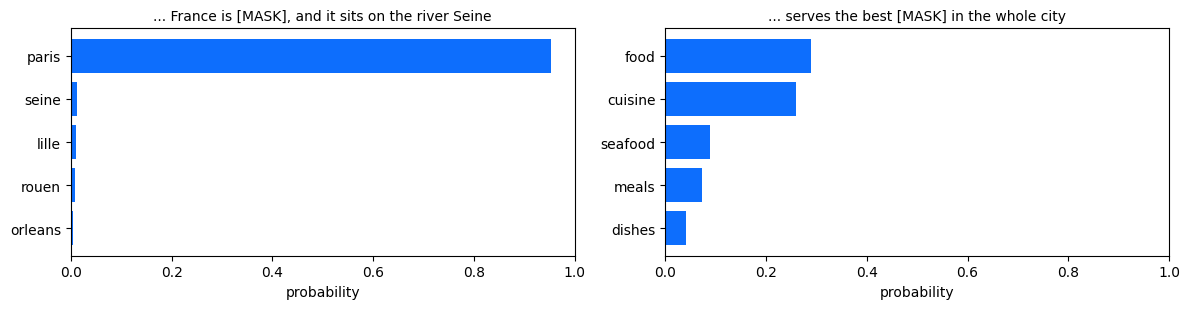

In [ ]:
def top_k(text, word, k=5):
    # 1. tokenize and get ids
    tokens = tokenizer.convert_ids_to_tokens(tokenizer(text)["input_ids"])
    ids = torch.tensor(tokenizer(text)["input_ids"])

    # 2. find index of word and mask it
    position = tokens.index(word)
    masked_ids = ids.clone()
    masked_ids[position] = tokenizer.mask_token_id

    # 3. run the model under torch.no_grad()
    with torch.no_grad():
        outputs = model(masked_ids.unsqueeze(0))

    # 4. calculate softmax and get topk
    logits = outputs.logits[0, position]
    probs = torch.softmax(logits, dim=-1)
    top = probs.topk(k)

    # 5. return token strings and float probabilities
    top_tokens = tokenizer.convert_ids_to_tokens(top.indices)
    top_probs = top.values.tolist()
    return top_tokens, top_probs

tokens_fact, probs_fact = top_k(DEMO_FACT, "paris")
tokens_vague, probs_vague = top_k(DEMO_VAGUE, "pizza")

p_constrained = probs_fact[0]
p_vague = probs_vague[0]

fig = show_predictions([
    ("... France is [MASK], and it sits on the river Seine", tokens_fact, probs_fact),
    ("... serves the best [MASK] in the whole city", tokens_vague, probs_vague),
])

In [ ]:
check_prediction_figure(fig, p_constrained, p_vague)

[ok] 2c: constrained 0.953 against unconstrained 0.289, a factor of 3.3
     The width of the softmax is the model's uncertainty, and it is a property of the context, not of the word.


---

# Exercise 3 — The attention matrix

The notes define the attention weights as a softmax over the dot products of one query
with every key, giving an $N \times N$ matrix of non-negative numbers whose rows sum to
one. BERT has twelve layers of twelve heads, so one forward pass produces 144 of them.

### 3a · Pull it out and check its shape — *Your turn*

Run the model on the masked `DEMO_FACT` sentence from 2a with `output_attentions=True`,
and stack `outputs.attentions` — a tuple of twelve tensors, each
`(1, heads, N, N)` — into one tensor `attn` of shape `(layers, heads, N, N)`.

`torch.stack(...)` gives `(12, 1, 12, N, N)`; the batch dimension of size 1 has to go.

In [ ]:
# 1. run the model on masked_ids.unsqueeze(0) with output_attentions=True
with torch.no_grad():
    outputs = model(masked_ids.unsqueeze(0), output_attentions=True)

# 2. attn = torch.stack(outputs.attentions) and drop the batch dimension
# outputs.attentions is a 12-tuple of (1, heads, N, N) tensors.
# torch.stack gives a tensor of shape (12, 1, 12, N, N).
# We use squeeze(1) to drop the batch dimension of size 1.
attn = torch.stack(outputs.attentions).squeeze(1)

# 3. print attn.shape, attn.min(), and the row sums
print("Attention tensor shape:", attn.shape)
print("Minimum attention value:", attn.min().item())
# Each row of the attention matrix must sum to 1.
# Let's verify this for one of the matrices (e.g., layer 0, head 0, row 0).
print("Row sums (should be 1s):", attn[0, 0, 0].sum().item())

Attention tensor shape: torch.Size([12, 12, 18, 18])
Minimum attention value: 2.475513588876769e-14
Row sums (should be 1s): 0.9999999403953552


In [ ]:
check_attention(attn)

[ok] 3a: attention stack (12, 12, 18, 18), all entries >= 0, every row sums to 1.
     12 x 12 = 144 matrices, each 18 x 18. Both of the last two dimensions are N, which is where the O(N^2) cost of self-attention comes from.


### 3b · Which head carries the answer — *Your turn*

The masked position has to get `paris` from somewhere, and `france` four tokens earlier is
the obvious source. Find the head that routes the most attention along that edge.

For every layer $\ell$ and head $h$, the weight from the mask to `france` is

```python
attn[l, h, position, france_index]
```

— row = the position doing the attending (the query), column = the position attended to
(the key). Search all 144, keep the largest, and draw that head's full matrix with

```python
fig_attn = show_attention(attn[best_layer, best_head], fact_tokens, title="...")
```

Best Layer: 9
Best Head: 2
Attention Weight: 0.5971


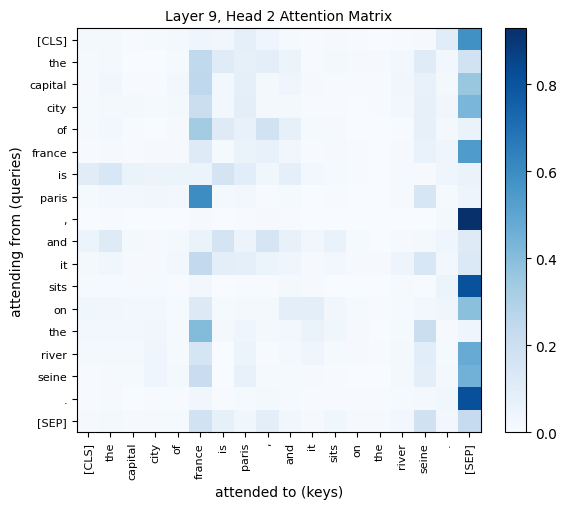

In [ ]:
france_index = fact_tokens.index("france")

# 1. loop over all layers and heads, reading attn[l, h, position, france_index]
# 2. keep best_weight and the best_layer / best_head that produced it
#    (torch.argmax on attn[:, :, position, france_index] also works)
# 3. print them, then draw that head with show_attention into `fig_attn`

# Initialize variables
best_weight = -1.0
best_layer = -1
best_head = -1

# Loop over all 12 layers and 12 heads
for l in range(attn.shape[0]):
    for h in range(attn.shape[1]):
        weight = attn[l, h, position, france_index].item()
        if weight > best_weight:
            best_weight = weight
            best_layer = l
            best_head = h

print(f"Best Layer: {best_layer}")
print(f"Best Head: {best_head}")
print(f"Attention Weight: {best_weight:.4f}")

# Visualize the attention matrix of this head
fig_attn = show_attention(
    attn[best_layer, best_head],
    fact_tokens,
    title=f"Layer {best_layer}, Head {best_head} Attention Matrix"
)


In [ ]:
check_routing(best_layer, best_head, best_weight, fig_attn)

[ok] 3b: layer 9, head 2 routes 0.597 of the masked position's attention onto 'france'.
     That connection is not in the weights. It was computed from this sentence, which is what 'dynamic routing' means in the notes.


---

## What this lab covered, and what it did not

Measured, on your own numbers:

- **Sub-word tokenization** spells a word the vocabulary does not hold out of pieces it
  does, so any string becomes a sequence of indices into a fixed vocabulary of 30 522.
- **Embedding** is a lookup: index $n$ selects row $n$ of a $30522 \times 768$ matrix.
- **Masked language modelling** recovers more than half of the hidden tokens exactly, and
  three quarters within its top five, using nothing but the tokens around them. That is
  the encoder's bidirectional context, and the objective BERT was trained with.
- **Confidence is a property of the context**, not of the word: the same model is at
  $0.95$ on one mask and $0.29$ on another.
- **The attention weights** are 144 matrices of shape $N \times N$, non-negative, each row
  summing to one — and one particular head connects the mask to the word that settles it.
  That connection lives in this sentence, not in the weights.

Out of scope here, and covered in the lecture notes:

- training or fine-tuning a transformer, and writing self-attention from scratch;
- **positional encoding** — self-attention is permutation-equivariant, so order has to be
  added to the inputs; nothing above would change if the tokens were shuffled;
- **multi-head** recombination, the $\sqrt{D_q}$ scaling, LayerNorm and the residual
  connections — the parts of the transformer layer around the attention;
- **decoder** models and autoregressive next-token prediction, and the encoder–decoder
  pair joined by cross-attention. BERT is one of the three families;
- the $O(N^2)$ cost that 3a's shape makes visible, and the sparsification, low-rank and
  kernel methods that reduce it;
- transformers over images.